# Function to automatic merge and fill missing values



## Create the function
You have to create a function which take 2 arguments :
- argument 1 : DataFrame main
- argument 2 : DataFrame opinion

Your function will return a new DataFrame which is the left merge of both DataFrames, and which has no missing values (so your function has to fill them), add new columns (flag, MONTH and DAY), and OPINION should be translated.

So you have to copy each useful code from the previous quests, and integrate it into a function. **This should achieve the same results as the previous quests.**

In [1]:
import pandas as pd

In [2]:
# Chargement des Datasets

link_main = "https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_main_2018.csv"
link_opinion = "https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_opinion_2018.csv"
df_main = pd.read_csv(link_main)
df_opinion = pd.read_csv(link_opinion)


In [3]:
# Affichage des premières lignes de df_main
df_main.head()


,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,PRESSURE_MAX_MB,CLOUDCOVER_AVG_PERCENT,HEATINDEX_MAX_C,DEWPOINT_MAX_C,WINDTEMP_MAX_C
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,1018,41.750,12,8,7
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,1020,87.875,13,12,6
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,1017,91.500,15,13,7
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,1011,90.125,14,12,10
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,1005,62.375,12,10,7


In [4]:
# Affichage des premières lignes de df_opinion
df_opinion.head()

,date,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION
0,2018-01-01,113,0,3,5.1,bad
1,2018-03-12,119,0,2,8.8,bad
2,2018-03-09,116,0,3,10.2,bad
3,2018-10-07,122,0,1,5.6,bad
4,2018-06-18,119,0,1,12.9,bad


In [5]:
# Affichage du nombre de lignes et de colonnes de df_main
df_main.shape

(365, 15)

In [6]:
# Affichage des informations de df_main
df_main.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    365 non-null    str    
 1   MAX_TEMPERATURE_C       365 non-null    int64  
 2   MIN_TEMPERATURE_C       365 non-null    int64  
 3   WINDSPEED_MAX_KMH       365 non-null    int64  
 4   TEMPERATURE_MORNING_C   365 non-null    int64  
 5   TEMPERATURE_NOON_C      365 non-null    int64  
 6   TEMPERATURE_EVENING_C   365 non-null    int64  
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64  
 9   VISIBILITY_AVG_KM       365 non-null    float64
 10  PRESSURE_MAX_MB         365 non-null    int64  
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64
 12  HEATINDEX_MAX_C         365 non-null    int64  
 13  DEWPOINT_MAX_C          365 non-null    int64  
 14  WINDTEMP_MAX_C          365 non-null    int64  
dtype

In [11]:
# Nombre de valeurs nulles de df_main
df_main.isna().sum()

DATE                      0
MAX_TEMPERATURE_C         0
MIN_TEMPERATURE_C         0
WINDSPEED_MAX_KMH         0
TEMPERATURE_MORNING_C     0
TEMPERATURE_NOON_C        0
TEMPERATURE_EVENING_C     0
PRECIP_TOTAL_DAY_MM       0
HUMIDITY_MAX_PERCENT      0
VISIBILITY_AVG_KM         0
PRESSURE_MAX_MB           0
CLOUDCOVER_AVG_PERCENT    0
HEATINDEX_MAX_C           0
DEWPOINT_MAX_C            0
WINDTEMP_MAX_C            0
dtype: int64

In [ ]:
# Nombre de lignes et de colonnes de df_opinion
df_opinion.shape

(341, 6)

In [33]:
df_opinion['OPINION'].unique()

<StringArray>
['bad', 'good', 'not good not bad', 'very bad', 'very good']
Length: 5, dtype: str

In [34]:
# Création d'une fonction merge_and_fill qui prend en paramètre
# deux DataFrame pour les joindre avec un left join sur la colonne de date

from datetime import datetime

def merge_and_fill(DataFrameMain, DataFrameOpinion):
  # MERGE BOTH DATAFRAMES
  NewDataFrame = pd.merge(DataFrameMain, DataFrameOpinion, how="left", left_on="DATE", right_on="date").drop(columns='date')
  NewDataFrame['FLAG'] = NewDataFrame['OPINION'].isna()
  mean_weather_column = round(NewDataFrame['WEATHER_CODE_EVENING'].mean(), 2)     #You have to complete this
  NewDataFrame.fillna({'WEATHER_CODE_EVENING':mean_weather_column},
                                      inplace = True) 
  NewDataFrame.fillna({'TOTAL_SNOW_MM':0},
                                      inplace = True)
  NewDataFrame.fillna({'UV_INDEX':NewDataFrame['UV_INDEX'].median()},
                                      inplace = True)
  NewDataFrame['SUNHOUR'] = NewDataFrame['SUNHOUR'].bfill()
  NewDataFrame.fillna({'OPINION':'Unknown'},inplace = True)
  NewDataFrame['DATE'] = pd.to_datetime(NewDataFrame['DATE'])
  NewDataFrame['MONTH'] = NewDataFrame['DATE'].dt.month
  NewDataFrame['DAY'] = NewDataFrame['DATE'].dt.day
  NewDataFrame['OPINION'] = NewDataFrame['OPINION'].replace({'bad': 'mauvais', 'good': 'bon',
  'very bad': 'très mauvais', 'very good': 'très bon', 'not good not bad': 'mitigé' })
  # FILL IN MISSING VALUES
  # WEATHER_CODE_EVENING => mode

  # TOTAL_SNOW_MM => moyenne

  # UV_INDEX => médiane

  # SUNHOUR => bfill

  # OPINION => remplacer les nuls par "Unknown"

  # Ajout de la colonne FLAG pour OPINION nulles

  # Conversion de la colonne DATE au format Datetime

  # Création de la colonne MONTH

  # Création de la colonne DAY

  # Tradudction de la colonne OPINION en français (créer une fonction)

  # Return new merged dataframe
  return NewDataFrame

In [35]:
df_2018 = merge_and_fill(df_main, df_opinion)

In [37]:
# Afficher le nombre de lignes et de colonnes de df_2018
# Afficher les premières ignes de df_2018
df_2018.shape

df_2018.head(5)

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,FLAG,MONTH,DAY
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,...,8,7,113.0,0.0,3.0,5.1,mauvais,False,1,1
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,...,12,6,122.0,0.0,3.0,3.3,mauvais,False,1,2
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,...,13,7,122.0,0.0,3.0,3.3,mauvais,False,1,3
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,...,12,10,116.0,0.0,3.0,3.3,mauvais,False,1,4
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,...,10,7,116.0,0.0,3.0,6.9,mauvais,False,1,5


In [38]:
# Afficher les informations de df_2018
df_2018.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   DATE                    365 non-null    datetime64[us]
 1   MAX_TEMPERATURE_C       365 non-null    int64         
 2   MIN_TEMPERATURE_C       365 non-null    int64         
 3   WINDSPEED_MAX_KMH       365 non-null    int64         
 4   TEMPERATURE_MORNING_C   365 non-null    int64         
 5   TEMPERATURE_NOON_C      365 non-null    int64         
 6   TEMPERATURE_EVENING_C   365 non-null    int64         
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64       
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64         
 9   VISIBILITY_AVG_KM       365 non-null    float64       
 10  PRESSURE_MAX_MB         365 non-null    int64         
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64       
 12  HEATINDEX_MAX_C         365 non-null    int64         
 13  D

## Execution with a loop
You will execute your function in a 9 rounds loop, once per year, and agregate this in a new big DataFrame with 24 columns and lots of rows.

In [39]:
# Chaque année entre 2010 et 2018 (inclus) a deux 2 sources : weather_main_YYYY.csv and weather_opinion_YYYY.csv
# Charger les deux datasets et joingez-les grâce à la fonction merge_and_fill
# Concaténez ce nouveau DataFrame au(x) précédent(s) pour n'obtenir qu'un long DataFrame df_weather


# Créez la boucle :
df_weather = pd.DataFrame()

for year in range(2010, 2019):
    link_main = f"https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_main_{year}.csv"
    link_opinion = f"https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_opinion_{year}.csv"

    df_main_year = pd.read_csv(link_main)
    df_opinion_year = pd.read_csv(link_opinion)

    df_year = merge_and_fill(df_main_year, df_opinion_year)
    df_weather = pd.concat([df_weather, df_year], ignore_index=True)



In [42]:
# Affichage des premières lignes de df_weather
df_weather.head(5)

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,FLAG,MONTH,DAY
0,2010-01-01,5,2,19,2,5,3,0.0,86,10.000,...,3,-1,119.0,0.0,1.0,5.1,très mauvais,False,1,1
1,2010-01-02,5,-1,6,-1,4,1,0.0,78,10.000,...,0,2,116.0,0.0,1.0,8.7,très mauvais,False,1,2
2,2010-01-03,5,1,26,2,4,2,0.3,61,9.875,...,0,-3,119.0,0.0,1.0,6.9,très mauvais,False,1,3
3,2010-01-04,1,-4,25,-2,0,-3,0.0,75,10.000,...,0,-9,113.0,0.0,1.0,8.7,très mauvais,False,1,4
4,2010-01-05,2,-5,20,-5,1,-4,0.0,71,10.000,...,0,-10,113.0,0.0,1.0,8.7,très mauvais,False,1,5


In [43]:
# Création d'une fonction clean qui :
# * crée une colonne FLAG indiquant une valeur manquante
# * convertit la colonne DATE au format datetime
# * traduit l'opinion en français

def clean(DataFrameYear):
  DataFrameYear = DataFrameYear.copy()

  # ALIGN DATAFRAME SHAPE, DATATYPE
  # On supprime les colonnes qui n'existent pas dans les années 2010 à 2018
  colonnes_en_trop = ['WEATHER_CODE_MORNING', 'WEATHER_CODE_NOON', 'SUNSET', 'SUNRISE', 'TEMPERATURE_NIGHT_C']
  DataFrameYear = DataFrameYear.drop(columns=colonnes_en_trop, errors='ignore')

  # Colonne FLAG
  DataFrameYear['FLAG'] = DataFrameYear['OPINION'].isna()

  # Colone DATE
  DataFrameYear['DATE'] = pd.to_datetime(DataFrameYear['DATE'])
  # MONTH et DAY sont recalculés à partir de DATE (absentes des fichiers 2021 et 2022)
  DataFrameYear['MONTH'] = DataFrameYear['DATE'].dt.month
  DataFrameYear['DAY'] = DataFrameYear['DATE'].dt.day

  # Colonne OPINION
  # 2019-2020 : opinions en anglais / 2021-2022 : opinions déjà en français, mais avec d'autres libellés
  traductions = {
      'very good': 'très bon', 'good': 'bon', 'not good not bad': 'mitigé',
      'bad': 'mauvais', 'very bad': 'très mauvais',
      'météo idéale': 'très bon', 'météo favorable': 'bon', 'météo correcte': 'mitigé',
      'météo défavorable': 'mauvais', 'météo très défavorable': 'très mauvais',
  }
  DataFrameYear['OPINION'] = DataFrameYear['OPINION'].replace(traductions)

  # Return new cleaned dataframe
  return DataFrameYear

In [44]:
# On crée une liste de DataFrames pour les années 2019 à 2022 (inclus)

links = {}
for year in range(2019, 2023):
    # Collect both DataFrames each year
    year = str(year)
    links[year] = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather" + year + ".csv"

# Create dataframes from the links to clean
dfs = {}  # Dictionary to store dataframes
for year, link in links.items():
    dfs[year] = pd.read_csv(link)
    dfs[year] = clean(dfs[year])

dfs['2019']

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,MONTH,DAY,FLAG
0,2019-01-01,9,4,10,4,7,8,0.2,94,9.000,...,6,3,176,0,1,5.1,très mauvais,1,1,False
1,2019-01-02,8,5,18,7,7,5,0.0,90,9.000,...,6,3,116,0,1,8.7,très mauvais,1,2,False
2,2019-01-03,6,0,18,0,4,3,0.0,88,10.000,...,1,-4,116,0,1,8.7,très mauvais,1,3,False
3,2019-01-04,5,-1,15,-1,4,3,0.0,91,10.000,...,1,-4,122,0,1,5.1,très mauvais,1,4,False
4,2019-01-05,6,-1,8,-1,4,3,0.0,91,8.000,...,2,-2,116,0,1,8.7,très mauvais,1,5,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2019-12-27,13,10,13,10,12,11,0.0,96,7.375,...,10,8,116,0,1,8.7,mitigé,12,27,False
361,2019-12-28,11,5,12,7,8,8,0.0,93,7.625,...,9,4,116,0,1,6.9,très mauvais,12,28,False
362,2019-12-29,9,2,11,3,6,7,0.0,86,10.000,...,4,0,116,0,1,8.7,très mauvais,12,29,False
363,2019-12-30,12,4,7,5,9,9,0.0,61,10.000,...,4,4,113,0,1,8.7,très mauvais,12,30,False


In [45]:
# Concaténez df_weather avec df_2019 à 2022
# Attention : à ne lancer qu'une fois après la boucle 2010-2018, sinon les années 2019 à 2022 seront ajoutées en double
df_weather = pd.concat([df_weather] + list(dfs.values()), ignore_index=True)
df_weather.shape

(4748, 23)

In [46]:
# Affichez les premières lignes de df_weather
df_weather.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,FLAG,MONTH,DAY
0,2010-01-01,5,2,19,2,5,3,0.0,86,10.000,...,3,-1,119.0,0.0,1.0,5.1,très mauvais,False,1,1
1,2010-01-02,5,-1,6,-1,4,1,0.0,78,10.000,...,0,2,116.0,0.0,1.0,8.7,très mauvais,False,1,2
2,2010-01-03,5,1,26,2,4,2,0.3,61,9.875,...,0,-3,119.0,0.0,1.0,6.9,très mauvais,False,1,3
3,2010-01-04,1,-4,25,-2,0,-3,0.0,75,10.000,...,0,-9,113.0,0.0,1.0,8.7,très mauvais,False,1,4
4,2010-01-05,2,-5,20,-5,1,-4,0.0,71,10.000,...,0,-10,113.0,0.0,1.0,8.7,très mauvais,False,1,5


# Draw a scatterplot
With Date on X-Axis and Max Temperature on Y-axis

The result must have 11 seasonality for the 11 summers/winters alternance.

Utilisez Seaborn ou Plotly Express selon votre préférence




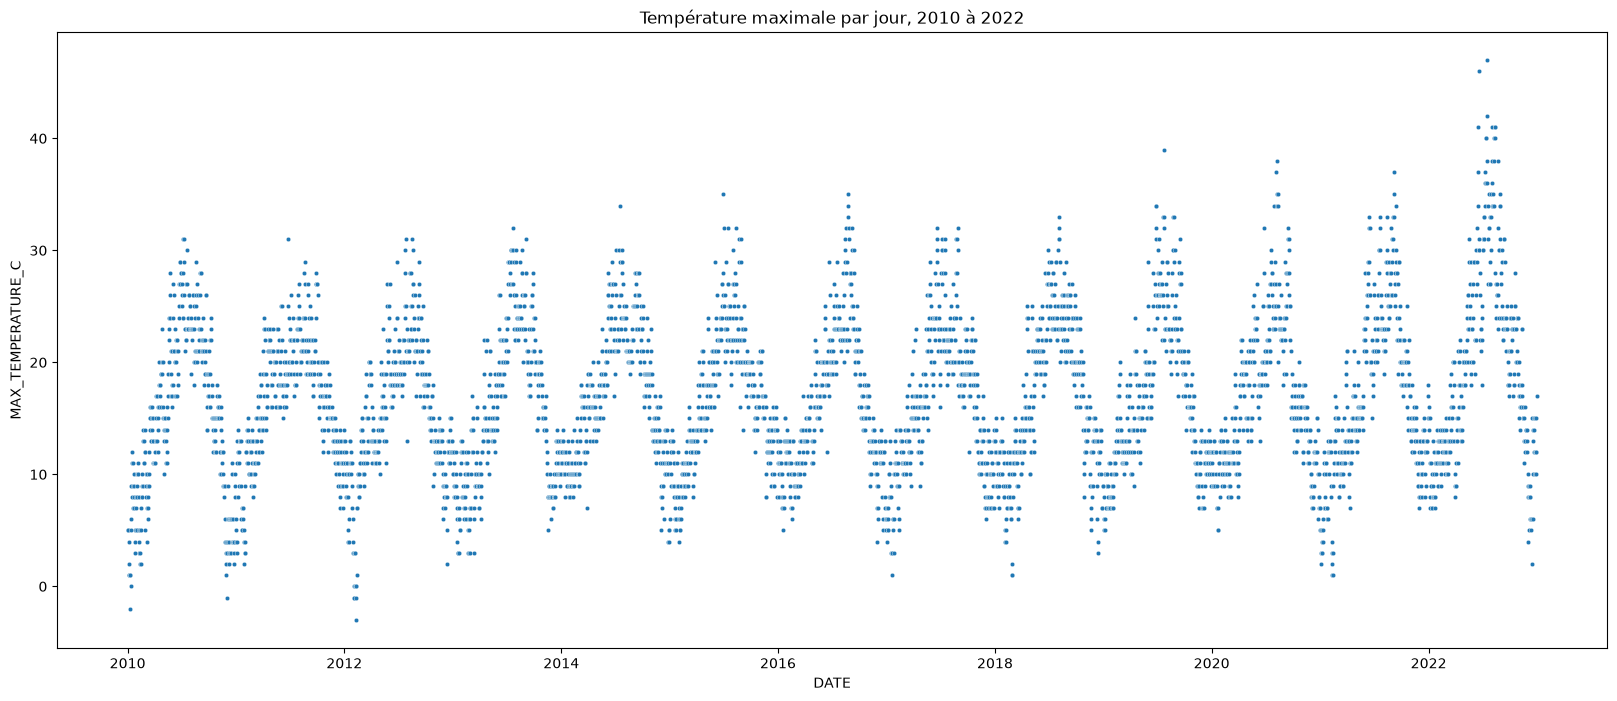

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(20, 8))
sns.scatterplot(data=df_weather, x='DATE', y='MAX_TEMPERATURE_C', s=10, ax=ax)
ax.set_title('Température maximale par jour, 2010 à 2022')
plt.show()


Find appropriate dataviz to answer to this question :

Which year had the best weather? Are years very different or not ?


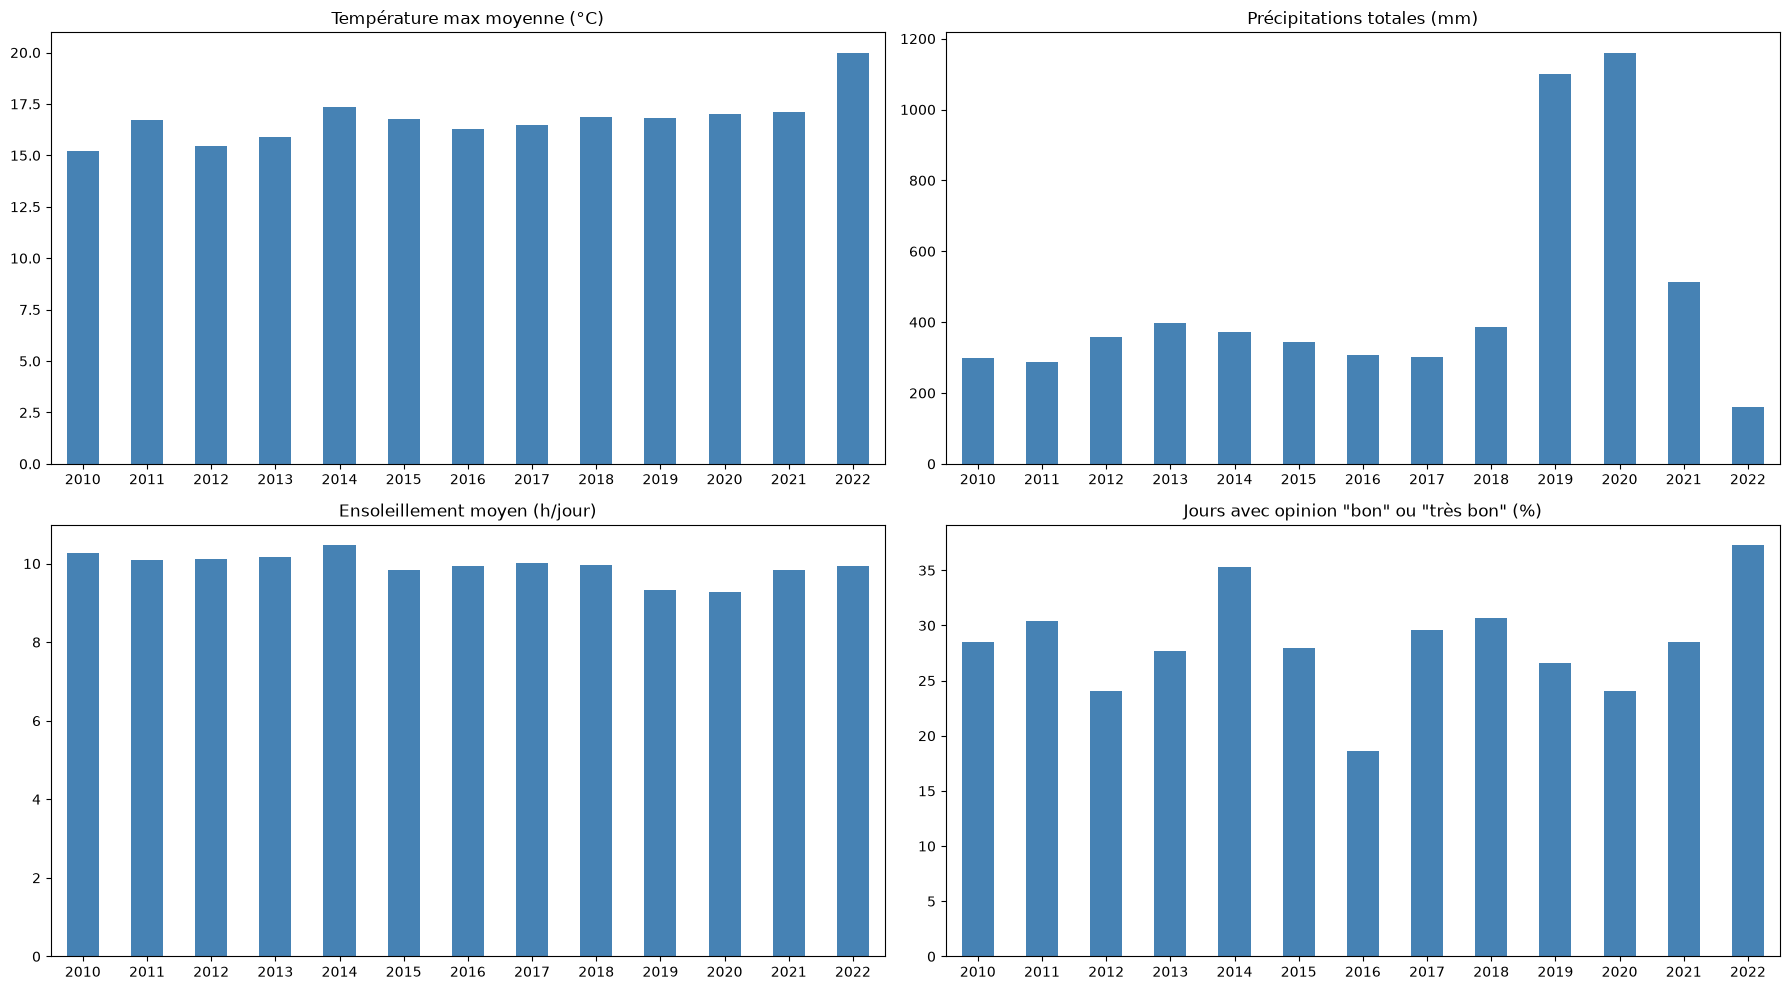

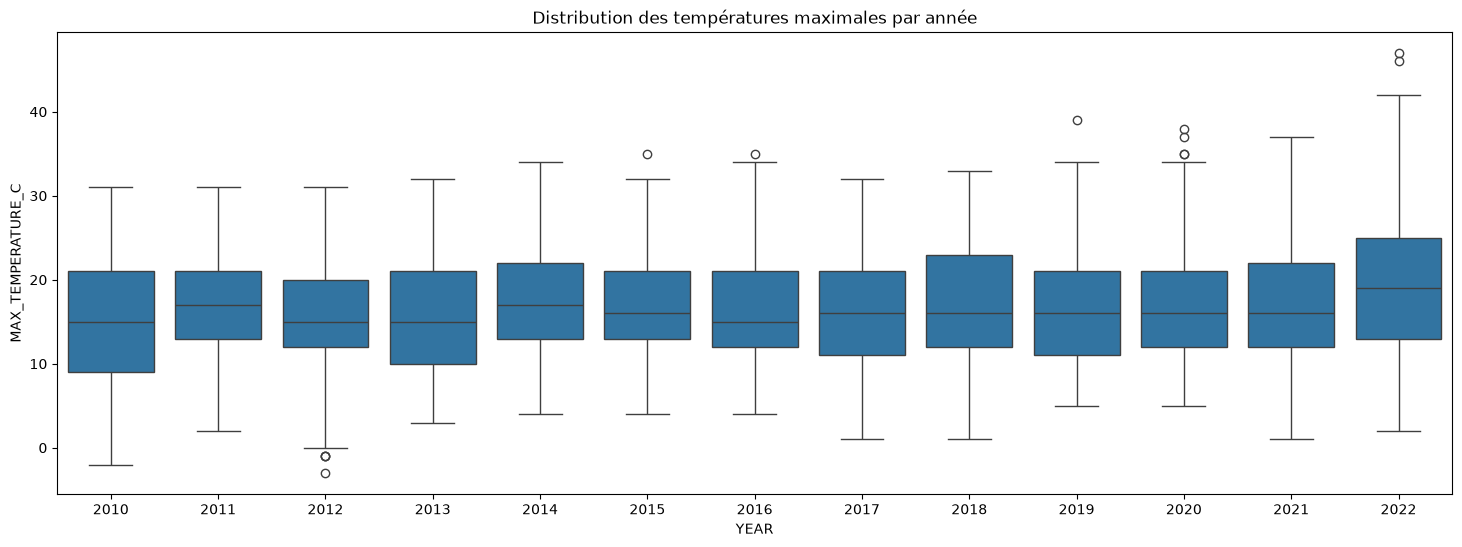

,temperature_max_moyenne,precipitations_totales,ensoleillement_moyen,part_jours_beau_temps
YEAR,,,,
2010,15.2,299.1,10.3,28.5
2011,16.7,287.7,10.1,30.4
2012,15.5,357.1,10.1,24.0
2013,15.9,398.6,10.2,27.7
2014,17.4,371.7,10.5,35.3
2015,16.8,344.0,9.8,27.9
2016,16.3,306.3,9.9,18.6
2017,16.5,301.5,10.0,29.6
2018,16.9,386.1,10.0,30.7


In [48]:
# Un indicateur par graphique, calculé pour chaque année
df_weather['YEAR'] = df_weather['DATE'].dt.year
df_weather['BEAU_TEMPS'] = df_weather['OPINION'].isin(['bon', 'très bon'])

par_annee = df_weather.groupby('YEAR').agg(
    temperature_max_moyenne=('MAX_TEMPERATURE_C', 'mean'),
    precipitations_totales=('PRECIP_TOTAL_DAY_MM', 'sum'),
    ensoleillement_moyen=('SUNHOUR', 'mean'),
    part_jours_beau_temps=('BEAU_TEMPS', 'mean'),
)
par_annee['part_jours_beau_temps'] = par_annee['part_jours_beau_temps'] * 100

titres = {
    'temperature_max_moyenne': 'Température max moyenne (°C)',
    'precipitations_totales': 'Précipitations totales (mm)',
    'ensoleillement_moyen': 'Ensoleillement moyen (h/jour)',
    'part_jours_beau_temps': 'Jours avec opinion "bon" ou "très bon" (%)',
}

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()
for i, (colonne, titre) in enumerate(titres.items()):
    par_annee[colonne].plot.bar(ax=axes[i], rot=0, color='steelblue')
    axes[i].set_title(titre)
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

# Distribution des températures max par année : les années se ressemblent-elles ?
fig, ax = plt.subplots(figsize=(18, 6))
sns.boxplot(data=df_weather, x='YEAR', y='MAX_TEMPERATURE_C', ax=ax)
ax.set_title('Distribution des températures maximales par année')
plt.show()

par_annee.round(1)

Quelles années semblent avoir bénéficié des meilleures conditions météo ? Pour quelles raisons ?

### Réponse

**Les années se ressemblent beaucoup.** De 2010 à 2021, la température maximale moyenne reste entre 15 et 17,5 °C, l'ensoleillement entre 9 et 10,5 h par jour, et les boxplots ont des médianes et des étendues très proches. La saisonnalité (été / hiver) pèse bien plus que l'année.

**2022 se détache nettement :**
- l'année la plus chaude (20 °C de moyenne, contre 15 à 17 °C pour les autres, avec des pics au-delà de 40 °C) ;
- l'année la plus sèche (161 mm de précipitations) ;
- la plus grande part de jours jugés "bon" ou "très bon" (37 %).

Si "beau temps" veut dire chaud, sec et apprécié, **2022 est la meilleure année**, suivie de **2014** (17,4 °C, meilleur ensoleillement à 10,5 h par jour, 35 % de jours appréciés). Attention toutefois : la chaleur de 2022 correspond aussi à des épisodes caniculaires, ce qui n'est pas forcément du "beau temps".

**Les moins bonnes années** sont **2016** (seulement 19 % de jours appréciés) et **2012** (une des plus fraîches, 24 % de jours appréciés).

**Limites de l'analyse :**
- Les précipitations de 2019 et 2020 (environ 1 100 mm) sont environ 3 fois plus élevées que celles des autres années. Ces années viennent de fichiers différents, la mesure n'est probablement pas comparable : je ne les ai pas utilisées pour conclure.
- Les opinions de 2021 et 2022 utilisent d'autres libellés ("météo idéale", "météo favorable"...). Je les ai fait correspondre à l'échelle des autres années, mais ce n'est peut-être pas exactement la même grille.
- De 2010 à 2018, 179 jours sans opinion ont été remplis avec "Unknown" : ils comptent comme des jours non appréciés, ce qui sous-estime légèrement ces années.